In [1]:
#packages
import pandas as pd
import numpy as np

#visual packages
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:

#only using the cols mentioned
ratings_cols = ['user_id', 'recipe_id', 'rating']
ratings = pd.read_csv('RAW_interactions.csv', usecols=ratings_cols)

recipes_cols = ['id', 'name', 'ingredients', 'n_ingredients']
recipes = pd.read_csv('RAW_recipes.csv', usecols=recipes_cols)

print(ratings.head())
print(recipes.head())

print(ratings.shape)
print(recipes.shape)

print(ratings.dtypes)
print(recipes.dtypes)

print(ratings.describe())
print(recipes.describe())



   user_id  recipe_id  rating
0    38094      40893       4
1  1293707      40893       5
2     8937      44394       4
3   126440      85009       5
4    57222      85009       5
                                         name      id  \
0  arriba   baked winter squash mexican style  137739   
1            a bit different  breakfast pizza   31490   
2                   all in the kitchen  chili  112140   
3                          alouette  potatoes   59389   
4          amish  tomato ketchup  for canning   44061   

                                         ingredients  n_ingredients  
0  ['winter squash', 'mexican seasoning', 'mixed ...              7  
1  ['prepared pizza crust', 'sausage patty', 'egg...              6  
2  ['ground beef', 'yellow onions', 'diced tomato...             13  
3  ['spreadable cheese with garlic and herbs', 'n...             11  
4  ['tomato juice', 'apple cider vinegar', 'sugar...              8  
(1132367, 3)
(231637, 4)
user_id      int64
recipe_id    

In [3]:
#remove 0 ratings
ratings = ratings[ratings['rating'] >= 1]
ratings = ratings.dropna().reset_index(drop=True)
assert ratings['rating'].between(1, 5).all()

ratings.head()


,user_id,recipe_id,rating
0,38094,40893,4
1,1293707,40893,5
2,8937,44394,4
3,126440,85009,5
4,57222,85009,5


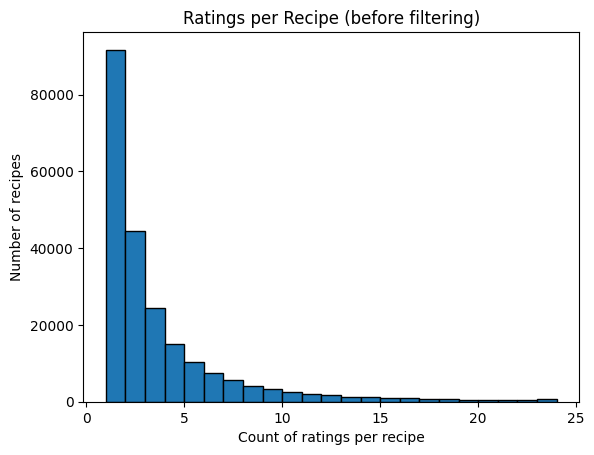

In [4]:
# Ratinger per recipe
recipe_count = ratings.groupby(['recipe_id'])['rating'].count()

plt.hist(recipe_count, bins=range(1, 25), edgecolor='black')

plt.xlabel('Count of ratings per recipe')
plt.ylabel('Number of recipes')
plt.title('Ratings per Recipe (before filtering)')

plt.show()
#40% of recipes have just one rating

In [5]:
print("ratings: ", len(ratings))
print("users: ", ratings['user_id'].nunique())
print("recipes:", ratings['recipe_id'].nunique())

ratings:  1071520
users:  196098
recipes: 226590


In [6]:
percent = 0.95

#ratings per recipe
recipe_count = ratings.groupby(['recipe_id'])['rating'].count().reset_index(name='count')

#only the 5% most rated
m = recipe_count['count'].quantile(percent)
q_recipes = recipe_count.copy().loc[recipe_count['count']>= m]

ratings = ratings[ratings['recipe_id'].isin(q_recipes['recipe_id'])]

print("min rating per recipe", m)
print("ratings now", len(ratings))
print("users now: ", ratings['user_id'].nunique())
print("recipes now", ratings['recipe_id'].nunique())

min rating per recipe 14.0
ratings now 473314
users now:  121994
recipes now 12487


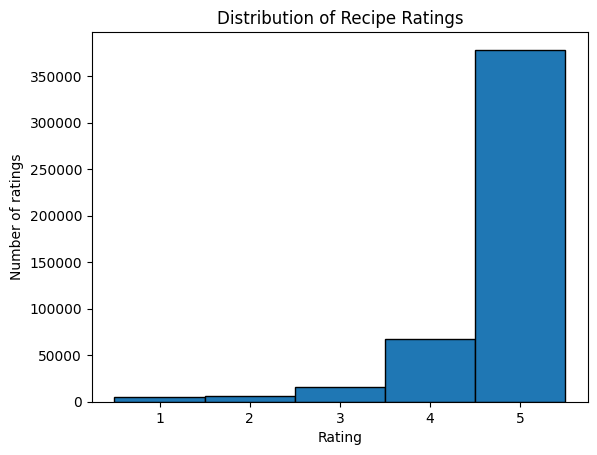

In [7]:
plt.hist(ratings['rating'], bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5], edgecolor='black')

plt.xlabel('Rating')
plt.ylabel('Number of ratings')
plt.title('Distribution of Recipe Ratings')
plt.xticks([1, 2, 3, 4, 5])

plt.show()

#most ratings are very high

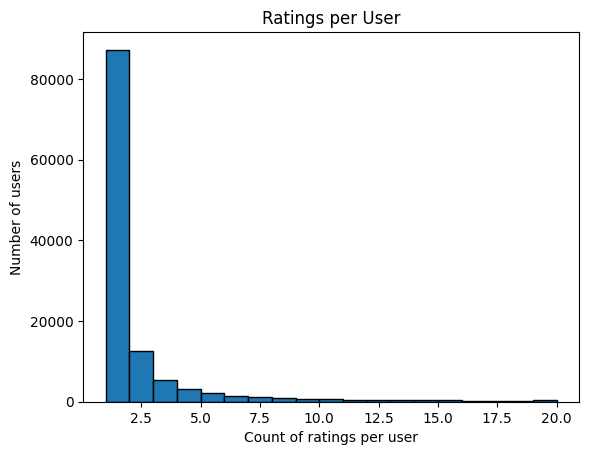

Users with only 1 rating: 87209
percentage of users with only 1 rating:  0.71


In [8]:
user_count = ratings.groupby(['user_id'])['rating'].count()

plt.hist(user_count, bins=range(1, 21), edgecolor='black')

plt.xlabel('Count of ratings per user')
plt.ylabel('Number of users')
plt.title('Ratings per User')

plt.show()

users_with_one_rating = user_count[user_count == 1]

print("Users with only 1 rating:", len(users_with_one_rating))
percentage = round(len(users_with_one_rating) / len(user_count), 2)
print("percentage of users with only 1 rating: ", percentage)

In [9]:
#average rating per recipe
recipe_avg_ratings = ratings.groupby(['recipe_id'])['rating'].mean().reset_index()

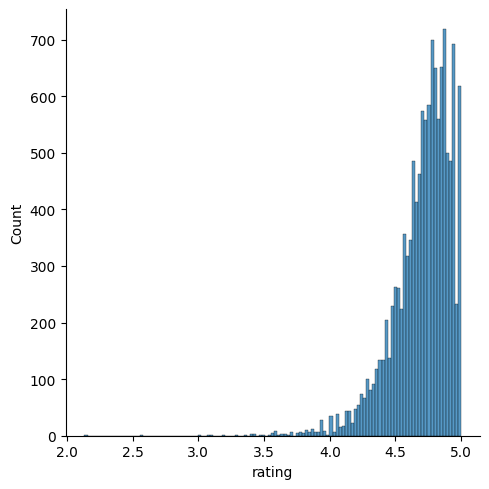

In [10]:
sns.displot(recipe_avg_ratings, x="rating")
#most recipes has an average between 4.5 and 5

In [11]:
#size of the two main tables
print("Ratings shape:", ratings.shape, "\n")

num_users = ratings['user_id'].nunique()
num_recipies = ratings['recipe_id'].nunique()
num_ratings = len(ratings)

print("Number of users:", num_users)
print("Number of recipes rated:", num_recipies, "\n")

#data density and sparsity
total_possible_ratings = num_users * num_recipies

density = num_ratings / total_possible_ratings
sparsity = 1 - density

print("number of ratings:", num_ratings)
print("Data density: {:.4%}".format(density))
print("Data sparsity: {:.4%}".format(sparsity))

Ratings shape: (473314, 3) 

Number of users: 121994
Number of recipes rated: 12487 

number of ratings: 473314
Data density: 0.0311%
Data sparsity: 99.9689%


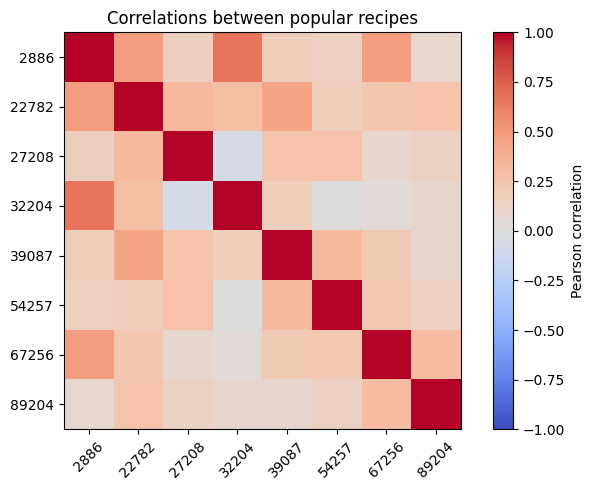

In [12]:
popular = ratings.groupby('recipe_id')['user_id'].nunique().nlargest(8).index
recipe_table = ratings[ratings['recipe_id'].isin(popular)].pivot_table(
    index='user_id', columns='recipe_id', values='rating', aggfunc='mean')

correlation = recipe_table.corr(min_periods=5)

plt.figure(figsize=(7, 5))
plt.imshow(correlation, vmin=-1, vmax=1, cmap='coolwarm')
plt.colorbar(label='Pearson correlation')
plt.xticks(range(len(correlation)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation)), correlation.index)
plt.title('Correlations between popular recipes')
plt.tight_layout()
plt.show()

In [13]:
#only recipes left in ratings
recipes = recipes[recipes['id'].isin(ratings['recipe_id'])]
print(recipes.shape)

#save cleaned data
ratings.to_csv('ratings_clean.csv', index=False)
recipes.to_csv('recipes_clean.csv', index=False)

(12487, 4)


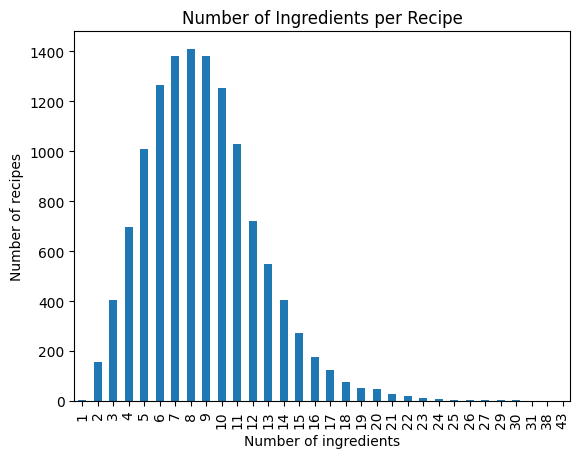

In [14]:
#Amount of ingredients per recipe
recipes['n_ingredients'].value_counts().sort_index().plot.bar(title='Number of Ingredients per Recipe')

plt.xlabel('Number of ingredients')
plt.ylabel('Number of recipes')
plt.show()

a